# Train and evaluate ConvNeXt Tiny classifier

This notebook trains a ConvNeXt Tiny model on annotated beach-cell matrices. It uses split metadata from `Data/Preprocessed`, loads five channels per target cell with optional neighboring-cell context from `/Volumes/BACKUPS/Piotr_beach/beach_all`, and evaluates the test set with per-class precision, recall, and F1 score.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "Source").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "Source").exists():
    raise RuntimeError("Could not locate project root containing Source directory.")

source_path = PROJECT_ROOT / "Source"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import (
    BeachCellDataset,
    FEATURE_SUFFIXES,
    class_weights,
    compute_channel_stats,
    find_missing_files,
    make_class_mapping,
    read_class_name_mapping,
    read_split_csv,
    summarize_nonfinite_values,
)
from Source.grid_search import run_grid_search
from Source.models import build_convnext_tiny
from Source.training import classification_metrics, fit_model, get_device, predict

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CELL_DATA_ROOT =PROJECT_ROOT /"pmaciag-volume-beach"/ "Data" / "Raw" / "beach_all"
CLASS_MAPPING_PATH = PROJECT_ROOT /"pmaciag-volume-beach"/ "Data" / "Raw" / "Classes.xlsx"
PREPROCESSED_DIR = PROJECT_ROOT /"pmaciag-volume-beach"/ "Data" / "Preprocessed"
OUTPUT_DIR = PROJECT_ROOT / "Results" / "convnext_tiny"

TRAIN_SPLIT = PREPROCESSED_DIR / "train_split.csv"
VALIDATION_SPLIT = PREPROCESSED_DIR / "validation_split.csv"
TEST_SPLIT = PREPROCESSED_DIR / "test_split.csv"

IMAGE_SIZE = 64
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS = 50
EARLY_STOPPING_PATIENCE = 5
EARLY_STOPPING_MIN_DELTA = 1e-4
USE_SPATIAL_AUGMENTATION = True
USE_PRETRAINED_IMAGENET_WEIGHTS = True
BASE_PARAMETER_GRID = [
    {"learning_rate": 1e-4, "weight_decay": 1e-4, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 3e-5, "weight_decay": 1e-4, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 1e-4, "weight_decay": 1e-3, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 3e-5, "weight_decay": 1e-3, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
]
CONTEXT_RADII = [0]
PARAMETER_GRID = [
    {**config, "context_radius": context_radius}
    for context_radius in CONTEXT_RADII
    for config in BASE_PARAMETER_GRID
]
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

print(f"Project root:    {PROJECT_ROOT}")
print(f"Cell data root:  {CELL_DATA_ROOT}")
print(f"Class mapping:   {CLASS_MAPPING_PATH}")
print(f"Output dir:      {OUTPUT_DIR}")
print(f"Feature order:   {FEATURE_SUFFIXES}")

Project root:    /workspace
Cell data root:  /workspace/pmaciag-volume-beach/Data/Raw/beach_all
Class mapping:   /workspace/pmaciag-volume-beach/Data/Raw/Classes.xlsx
Output dir:      /workspace/Results/convnext_tiny
Feature order:   ('r', 'g', 'b', 's', 'd')


In [3]:
train_df = read_split_csv(TRAIN_SPLIT)
validation_df = read_split_csv(VALIDATION_SPLIT)
test_df = read_split_csv(TEST_SPLIT)

class_to_idx = make_class_mapping(train_df, validation_df, test_df)
class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, class_to_idx.keys())
idx_to_class_code = {idx: label for label, idx in class_to_idx.items()}
idx_to_class_name = {
    idx: f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for idx, code in idx_to_class_code.items()
}

class_table = pd.DataFrame(
    [
        {"encoded_class": code, "model_index": idx, "class_name": class_name_by_code.get(code, f"class_{code}")}
        for code, idx in class_to_idx.items()
    ]
).sort_values("model_index")

if all(name == f"class_{code}" for code, name in class_name_by_code.items()):
    print(
        "No class-name mapping was detected in Classes.xlsx; "
        "using fallback labels class_0, class_1, ..."
    )

print(f"Train rows:      {len(train_df):,}")
print(f"Validation rows: {len(validation_df):,}")
print(f"Test rows:       {len(test_df):,}")
display(class_table)

Train rows:      3,456
Validation rows: 741
Test rows:       741


,encoded_class,model_index,class_name
0,0,0,Snow
1,1,1,Dry sediment
2,2,2,Wet sediment
3,3,3,Water
4,4,4,Bedrock
5,5,5,Boulder
6,6,6,Driftwood
7,7,7,Algae
8,8,8,Ice
9,9,9,Anthropogenic


In [4]:
all_splits_df = pd.concat([train_df, validation_df, test_df], ignore_index=True)

if not CELL_DATA_ROOT.exists():
    raise FileNotFoundError(
        f"External cell data directory not found: {CELL_DATA_ROOT}. "
        "Mount the external drive before running training."
    )

sanity_rows = all_splits_df.head(min(20, len(all_splits_df)))
missing_files = find_missing_files(sanity_rows, CELL_DATA_ROOT)

if not missing_files.empty:
    display(missing_files)
    raise FileNotFoundError(
        "Some target matrix files are missing in the external data root. "
        "Inspect the missing files above."
    )

print(
    f"External cell data root is available. "
    f"Checked {len(sanity_rows):,} target cells as a quick sanity check."
)
print(
    "Full target/context file availability is checked lazily while loading batches, "
    "which avoids a slow preflight scan of the external volume."
)

External cell data root is available. Checked 20 target cells as a quick sanity check.
Full target/context file availability is checked lazily while loading batches, which avoids a slow preflight scan of the external volume.


In [5]:
NONFINITE_SANITY_ROWS = train_df.head(min(20, len(train_df)))
nonfinite_values = summarize_nonfinite_values(NONFINITE_SANITY_ROWS, CELL_DATA_ROOT)
if nonfinite_values.empty:
    print(f"No NaN, -999, or infinite values found in {len(NONFINITE_SANITY_ROWS):,} sampled training target cells.")
else:
    display(
        nonfinite_values
        .groupby(["split" if "split" in nonfinite_values.columns else "date", "feature"], dropna=False)
        .agg(files=("path", "count"), nan_values=("nan_count", "sum"), inf_values=("inf_count", "sum"))
    )
    display(nonfinite_values.head(20))

channel_stats_cache = {}
base_channel_stats = compute_channel_stats(
    train_df,
    CELL_DATA_ROOT,
    FEATURE_SUFFIXES,
    context_radius=0,
)


def get_channel_stats(context_radius):
    context_radius = int(context_radius)
    if context_radius not in channel_stats_cache:
        channel_stats_cache[context_radius] = base_channel_stats
    return channel_stats_cache[context_radius]

stats_rows = []
for context_radius in sorted({int(config["context_radius"]) for config in PARAMETER_GRID}):
    mean, std = get_channel_stats(context_radius)
    for feature, feature_mean, feature_std in zip(FEATURE_SUFFIXES, mean, std):
        stats_rows.append(
            {
                "context_radius": context_radius,
                "feature": feature,
                "mean": feature_mean,
                "std": feature_std,
                "estimated_from": "training_target_cells_only",
            }
        )

stats_df = pd.DataFrame(stats_rows)
stats_df

No NaN, -999, or infinite values found in 20 sampled training target cells.


,context_radius,feature,mean,std,estimated_from
0,0,r,118.646523,47.892353,training_target_cells_only
1,0,g,122.686409,49.060795,training_target_cells_only
2,0,b,126.339005,50.661888,training_target_cells_only
3,0,s,17.467157,14.551807,training_target_cells_only
4,0,d,0.603658,1.108177,training_target_cells_only


In [6]:
def make_datasets(context_radius):
    channel_mean, channel_std = get_channel_stats(context_radius)
    train_dataset = BeachCellDataset(
        train_df,
        CELL_DATA_ROOT,
        class_to_idx,
        image_size=IMAGE_SIZE,
        mean=channel_mean,
        std=channel_std,
        augment=USE_SPATIAL_AUGMENTATION,
        context_radius=context_radius,
    )
    validation_dataset = BeachCellDataset(
        validation_df,
        CELL_DATA_ROOT,
        class_to_idx,
        image_size=IMAGE_SIZE,
        mean=channel_mean,
        std=channel_std,
        context_radius=context_radius,
    )
    test_dataset = BeachCellDataset(
        test_df,
        CELL_DATA_ROOT,
        class_to_idx,
        image_size=IMAGE_SIZE,
        mean=channel_mean,
        std=channel_std,
        context_radius=context_radius,
    )
    return train_dataset, validation_dataset, test_dataset, channel_mean, channel_std


def make_train_validation_loaders(config):
    context_radius = int(config["context_radius"])
    train_dataset, validation_dataset, _, _, _ = make_datasets(context_radius)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )
    return train_loader, validation_loader


sample_context_radius = int(PARAMETER_GRID[0]["context_radius"])
sample_train_dataset, _, _, sample_mean, sample_std = make_datasets(sample_context_radius)
sample_loader = DataLoader(
    sample_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

x_batch, y_batch = next(iter(sample_loader))
print(f"Sample context radius: {sample_context_radius}")
print(f"Input batch shape: {tuple(x_batch.shape)}")
print(f"Label batch shape: {tuple(y_batch.shape)}")

Sample context radius: 0
Input batch shape: (32, 5, 64, 64)
Label batch shape: (32,)


In [7]:
device = get_device()
weights = class_weights(train_df, class_to_idx)


def print_torch_device_diagnostics():
    import os
    import platform
    import sys

    print(f"Python executable: {sys.executable}")
    print(f"Python version:    {platform.python_version()}")
    print(f"PyTorch version:   {torch.__version__}")
    print(f"PyTorch path:      {torch.__file__}")
    print(f"CUDA build:        {torch.version.cuda}")
    print(f"CUDA available:    {torch.cuda.is_available()}")
    print(f"CUDA device count: {torch.cuda.device_count()}")
    print(f"CUDA_VISIBLE_DEVICES: {os.environ.get('CUDA_VISIBLE_DEVICES', '<not set>')}")
    if torch.cuda.is_available():
        current_index = torch.cuda.current_device()
        print(f"CUDA current device: {current_index}")
        for index in range(torch.cuda.device_count()):
            props = torch.cuda.get_device_properties(index)
            print(
                f"CUDA device {index}: {props.name}, "
                f"memory={props.total_memory / 1024**3:.2f} GiB, "
                f"capability={props.major}.{props.minor}"
            )
    mps_available = bool(getattr(torch.backends, "mps", None)) and torch.backends.mps.is_available()
    print(f"MPS available:     {mps_available}")


print_torch_device_diagnostics()


def model_factory(config):
    return build_convnext_tiny(
        num_classes=len(class_to_idx),
        in_channels=len(FEATURE_SUFFIXES),
        pretrained=bool(config["pretrained"]),
    )

print(f"Selected device: {device}")
print(f"Grid configurations: {len(PARAMETER_GRID)}")

Python executable: /usr/bin/python
Python version:    3.10.12
PyTorch version:   2.7.0+cu128
PyTorch path:      /usr/local/lib/python3.10/dist-packages/torch/__init__.py
CUDA build:        12.8
CUDA available:    True
CUDA device count: 3
CUDA_VISIBLE_DEVICES: <not set>
CUDA current device: 0
CUDA device 0: NVIDIA RTX 6000 Ada Generation, memory=47.50 GiB, capability=8.9
CUDA device 1: NVIDIA RTX 6000 Ada Generation, memory=47.50 GiB, capability=8.9
CUDA device 2: NVIDIA RTX 6000 Ada Generation, memory=47.50 GiB, capability=8.9
MPS available:     False
Selected device: cuda
Grid configurations: 4


In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = OUTPUT_DIR / "convnext_tiny_best.pt"

grid_result = run_grid_search(
    model_factory=model_factory,
    parameter_grid=PARAMETER_GRID,
    train_loader=None,
    validation_loader=None,
    loader_factory=make_train_validation_loaders,
    class_weights=weights,
    idx_to_class=idx_to_class_name,
    device=device,
    epochs=EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
    random_seed=RANDOM_SEED,
)

model = grid_result.model
history = grid_result.history
best_config = grid_result.config
validation_report = grid_result.validation_report
best_context_radius = int(best_config["context_radius"])
_, _, test_dataset, channel_mean, channel_std = make_datasets(best_context_radius)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

torch.save(
    {key: value.detach().cpu() for key, value in model.state_dict().items()},
    checkpoint_path,
)

best_config_path = OUTPUT_DIR / "best_config.json"
with best_config_path.open("w", encoding="utf-8") as file:
    json.dump(best_config, file, indent=2)

normalization_stats_path = OUTPUT_DIR / "normalization_stats.csv"
normalization_stats = pd.DataFrame(
    {
        "feature": FEATURE_SUFFIXES,
        "mean": channel_mean,
        "std": channel_std,
        "context_radius": best_context_radius,
    }
)
normalization_stats.to_csv(normalization_stats_path, index=False)

inference_metadata_path = OUTPUT_DIR / "inference_metadata.json"
inference_metadata = {
    "image_size": IMAGE_SIZE,
    "context_radius": best_context_radius,
    "context_window_size": 2 * best_context_radius + 1,
    "feature_suffixes": list(FEATURE_SUFFIXES),
    "class_to_idx": class_to_idx,
    "idx_to_class_code": idx_to_class_code,
    "class_name_by_code": class_name_by_code,
    "best_config": best_config,
    "channel_mean": [float(value) for value in channel_mean],
    "channel_std": [float(value) for value in channel_std],
}
with inference_metadata_path.open("w", encoding="utf-8") as file:
    json.dump(inference_metadata, file, indent=2)

best_validation_report_path = OUTPUT_DIR / "best_validation_classification_report.csv"
validation_report.to_csv(best_validation_report_path)

grid_search_summary_path = OUTPUT_DIR / "grid_search_summary.csv"
grid_result.summary.to_csv(grid_search_summary_path, index=False)

best_grid_result_path = OUTPUT_DIR / "best_grid_search_result.csv"
grid_result.summary.head(1).to_csv(best_grid_result_path, index=False)

grid_search_metric_trace_path = OUTPUT_DIR / "grid_search_validation_metric_trace.csv"
grid_result.metric_trace.to_csv(grid_search_metric_trace_path, index=False)

history_path = OUTPUT_DIR / "training_history.csv"
history.to_csv(history_path, index=False)

print(f"Best context radius: {best_context_radius}")
display(grid_result.summary.head(1))
history


Grid search run 1: {'learning_rate': 0.0001, 'weight_decay': 0.0001, 'pretrained': True, 'context_radius': 0}
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:01<00:00, 73.4MB/s] 


Epoch 001 | train loss=1.1316, acc=0.6655 | val loss=0.6251, acc=0.8030


Epoch 002 | train loss=0.4636, acc=0.8368 | val loss=0.5000, acc=0.8543


Epoch 003 | train loss=0.3136, acc=0.8892 | val loss=0.3629, acc=0.8812


...

Epoch 012 | train loss=0.0820, acc=0.9716 | val loss=0.3213, acc=0.9298


Epoch 013 | train loss=0.0699, acc=0.9792 | val loss=0.3550, acc=0.9055
Early stopping after epoch 013. Best validation loss was 0.3108 at epoch 008.


Validation macro F1: 0.8926
Best context radius: 0


,learning_rate,weight_decay,pretrained,context_radius,run_index,epochs_trained,best_validation_loss,best_validation_accuracy,validation_macro_f1
2,0.0001,0.001,True,0,3,13,0.319105,0.931174,0.924692


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,is_best_epoch
0,1,1.115525,0.660012,0.602054,0.794872,False
1,2,0.497117,0.827836,0.406058,0.874494,False
2,3,0.315676,0.885417,0.335065,0.881242,False
3,4,0.244726,0.910880,0.333446,0.900135,False
4,5,0.187855,0.935185,0.323078,0.910931,False
5,6,0.152932,0.942998,0.357750,0.896086,False
6,7,0.115613,0.959491,0.406015,0.892038,False
7,8,0.093784,0.963252,0.319105,0.921727,True
8,9,0.071223,0.971933,0.388337,0.906883,False
9,10,0.087791,0.972801,0.332002,0.910931,False


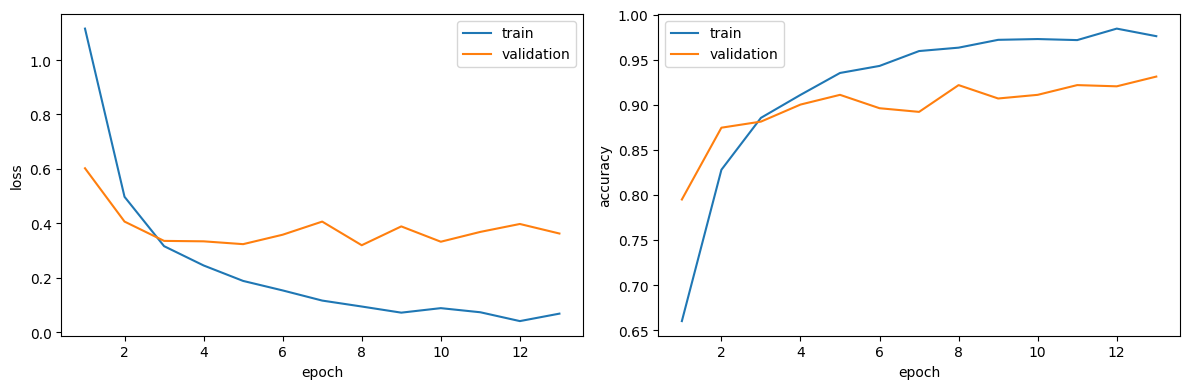

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], label="train")
axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], label="train")
axes[1].plot(history["epoch"], history["validation_accuracy"], label="validation")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_history.png", dpi=150)
plt.show()

In [10]:
y_true, y_pred, y_probability = predict(model, test_loader, device)
report_df, confusion_df = classification_metrics(y_true, y_pred, idx_to_class_name)

report_path = OUTPUT_DIR / "test_classification_report.csv"
confusion_path = OUTPUT_DIR / "test_confusion_matrix.csv"

report_df.to_csv(report_path)
confusion_df.to_csv(confusion_path)

report_df

,precision,recall,f1-score,support
0: Snow,0.875000,0.933333,0.903226,15.000000
1: Dry sediment,0.910891,0.876190,0.893204,105.000000
2: Wet sediment,0.868687,0.966292,0.914894,89.000000
3: Water,0.952941,0.975904,0.964286,83.000000
4: Bedrock,0.858586,0.850000,0.854271,100.000000
5: Boulder,0.950617,0.836957,0.890173,92.000000
6: Driftwood,0.987342,0.975000,0.981132,80.000000
7: Algae,0.931624,0.964602,0.947826,113.000000
8: Ice,0.900000,0.931034,0.915254,58.000000
9: Anthropogenic,1.000000,0.666667,0.800000,6.000000


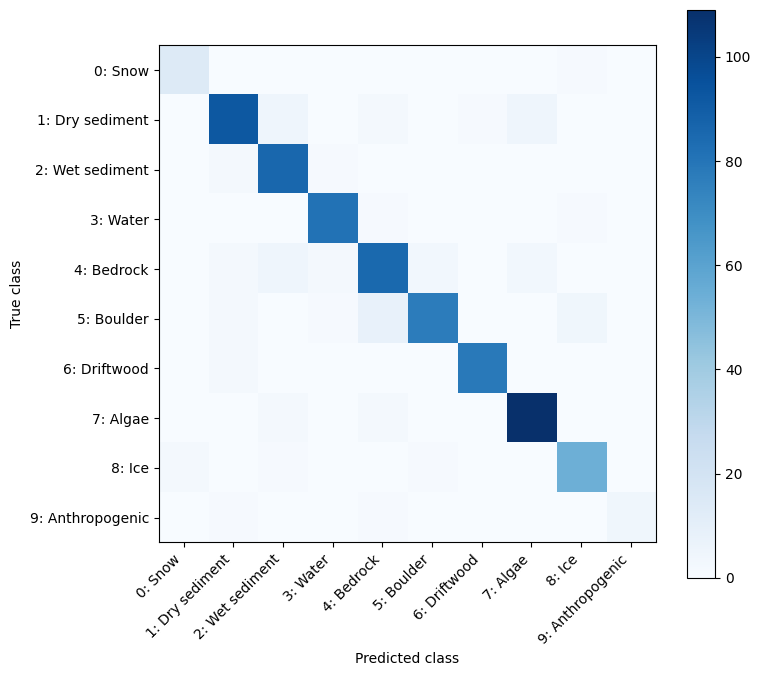

,0: Snow,1: Dry sediment,2: Wet sediment,3: Water,4: Bedrock,5: Boulder,6: Driftwood,7: Algae,8: Ice,9: Anthropogenic
0: Snow,14,0,0,0,0,0,0,0,1,0
1: Dry sediment,0,92,5,0,2,0,1,5,0,0
2: Wet sediment,0,2,86,1,0,0,0,0,0,0
3: Water,0,0,0,81,1,0,0,0,1,0
4: Bedrock,0,2,5,2,85,3,0,3,0,0
5: Boulder,0,2,0,1,8,77,0,0,4,0
6: Driftwood,0,2,0,0,0,0,78,0,0,0
7: Algae,0,0,2,0,2,0,0,109,0,0
8: Ice,2,0,1,0,0,1,0,0,54,0
9: Anthropogenic,0,1,0,0,1,0,0,0,0,4


In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(confusion_df.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(confusion_df.columns)))
ax.set_yticks(range(len(confusion_df.index)))
ax.set_xticklabels(confusion_df.columns, rotation=45, ha="right")
ax.set_yticklabels(confusion_df.index)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()

confusion_df

In [12]:
prediction_df = test_df.reset_index(drop=True).copy()
prediction_df["true_class_code"] = [idx_to_class_code[int(idx)] for idx in y_true]
prediction_df["predicted_class_code"] = [idx_to_class_code[int(idx)] for idx in y_pred]
prediction_df["true_class_name"] = [class_name_by_code[prediction_df.loc[i, "true_class_code"]] for i in range(len(prediction_df))]
prediction_df["predicted_class_name"] = [class_name_by_code[prediction_df.loc[i, "predicted_class_code"]] for i in range(len(prediction_df))]

for idx, class_code in idx_to_class_code.items():
    prediction_df[f"probability_class_{class_code}"] = y_probability[:, idx]

prediction_path = OUTPUT_DIR / "test_predictions.csv"
prediction_df.to_csv(prediction_path, index=False)

print(f"Saved checkpoint: {checkpoint_path}")
print(f"Saved best config: {best_config_path}")
print(f"Saved normalization stats: {normalization_stats_path}")
print(f"Saved inference metadata: {inference_metadata_path}")
print(f"Saved best validation report: {best_validation_report_path}")
print(f"Saved grid summary: {grid_search_summary_path}")
print(f"Saved best grid result: {best_grid_result_path}")
print(f"Saved grid metric trace: {grid_search_metric_trace_path}")
print(f"Saved history:    {history_path}")
print(f"Saved report:     {report_path}")
print(f"Saved confusion:  {confusion_path}")
print(f"Saved predictions:{prediction_path}")

prediction_df.head()

Saved checkpoint: /workspace/Results/convnext_tiny/convnext_tiny_best.pt
Saved best config: /workspace/Results/convnext_tiny/best_config.json
Saved normalization stats: /workspace/Results/convnext_tiny/normalization_stats.csv
Saved inference metadata: /workspace/Results/convnext_tiny/inference_metadata.json
Saved best validation report: /workspace/Results/convnext_tiny/best_validation_classification_report.csv
Saved grid summary: /workspace/Results/convnext_tiny/grid_search_summary.csv
Saved best grid result: /workspace/Results/convnext_tiny/best_grid_search_result.csv
Saved grid metric trace: /workspace/Results/convnext_tiny/grid_search_validation_metric_trace.csv
Saved history:    /workspace/Results/convnext_tiny/training_history.csv
Saved report:     /workspace/Results/convnext_tiny/test_classification_report.csv
Saved confusion:  /workspace/Results/convnext_tiny/test_confusion_matrix.csv
Saved predictions:/workspace/Results/convnext_tiny/test_predictions.csv


,date,cell_id,class,split,true_class_code,predicted_class_code,true_class_name,predicted_class_name,probability_class_0,probability_class_1,probability_class_2,probability_class_3,probability_class_4,probability_class_5,probability_class_6,probability_class_7,probability_class_8,probability_class_9
0,20180722,1014749,3,test,3,3,Water,Water,0.000022,0.000070,0.000316,0.999290,0.000091,0.000026,0.000051,0.000051,0.000039,0.000043
1,20180722,1042265,4,test,4,4,Bedrock,Bedrock,0.000506,0.000427,0.022533,0.002258,0.962753,0.009877,0.000120,0.000493,0.000875,0.000157
2,20180722,1043796,4,test,4,4,Bedrock,Bedrock,0.000401,0.000510,0.035621,0.002427,0.940129,0.018967,0.000293,0.000183,0.000382,0.001087
3,20180722,1051434,2,test,2,2,Wet sediment,Wet sediment,0.000040,0.000799,0.998476,0.000402,0.000038,0.000066,0.000030,0.000033,0.000027,0.000089
4,20180722,1054489,2,test,2,2,Wet sediment,Wet sediment,0.000040,0.000541,0.998483,0.000701,0.000090,0.000041,0.000018,0.000031,0.000018,0.000037
